In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from tqdm import tqdm
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_absolute_percentage_error, r2_score
from keras.models import Model
from keras.layers import Input, Dense, Dropout, LayerNormalization, GlobalAveragePooling1D
from keras.callbacks import EarlyStopping

!pip install keras-tcn
from tcn import TCN

In [3]:
data = pd.read_csv("bismillah data.csv")
data

,country,date,sector,GWh
0,Mexico,1/1/2022,Gas,493.556
1,Mexico,2/1/2022,Gas,493.653
2,Mexico,3/1/2022,Gas,494.662
3,Mexico,4/1/2022,Gas,498.657
4,Mexico,5/1/2022,Gas,499.937
...,...,...,...,...
1210,Mexico,26/04/2025,Gas,649.285
1211,Mexico,27/04/2025,Gas,651.161
1212,Mexico,28/04/2025,Gas,650.995
1213,Mexico,29/04/2025,Gas,654.125


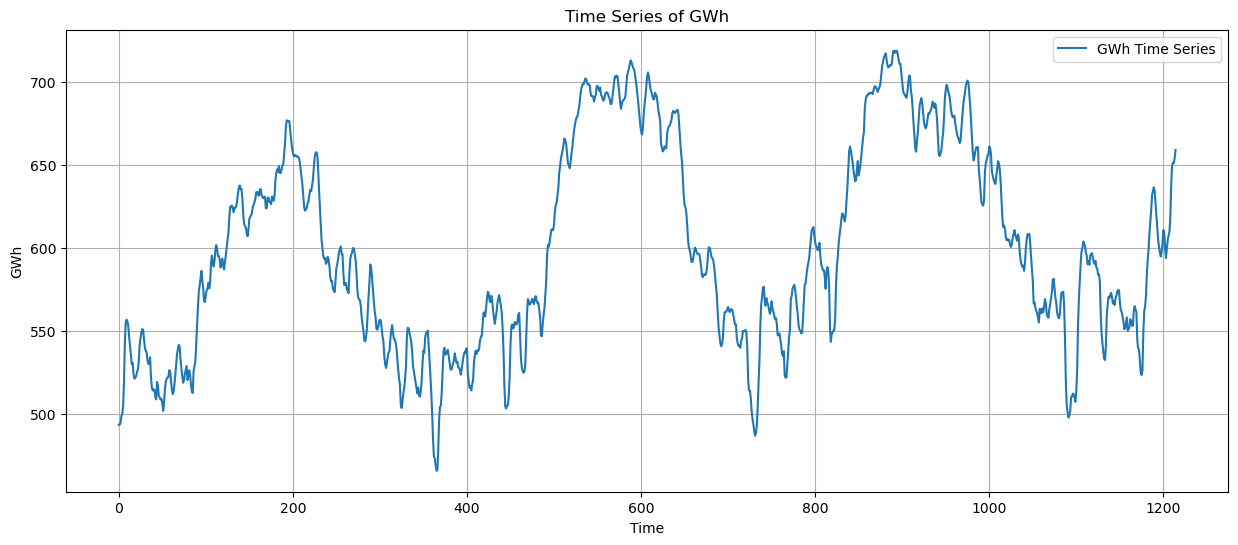

In [ ]:
# Plot Time Series GWh
import matplotlib.pyplot as plt
plt.figure(figsize=(15, 6))
plt.plot(data["GWh"], label='GWh Time Series')
plt.xlabel('Time')
plt.ylabel('GWh')
plt.title('Time Series of GWh')
plt.legend()
plt.grid(True)
plt.show()

In [4]:
# Data Preprocessing
df = data[["GWh"]].values
scaler = MinMaxScaler()
df_scaled = scaler.fit_transform(df)

In [5]:
lookback_window = 30

In [6]:
x = []
y = []
for i in tqdm(range(lookback_window, len(df_scaled))):
    x.append(df_scaled[i - lookback_window:i])
    y.append(df_scaled[i])

x = np.array(x)
y = np.array(y)
x = np.reshape(x, (x.shape[0], x.shape[1], 1))

100%|██████████| 1185/1185 [00:00<00:00, 728455.26it/s]


In [7]:
train_size = int(len(x) * 0.8)
x_train, x_val = x[:train_size], x[train_size:]
y_train, y_val = y[:train_size], y[train_size:]

In [ ]:
def build_model_tcn(hp):
    input_layer = Input(shape=(lookback_window, 1))

    # TCN Layer
    tcn_output = TCN(
        nb_filters=hp.Choice('nb_filters', [8, 16, 32, 64]),
        kernel_size=hp.Choice('kernel_size', [2, 3, 5]),
        nb_stacks=hp.Choice('nb_stacks', [1, 2]),
        dilations=[2**i for i in range(hp.Choice('n_dilations', [2, 3, 4]))],
        padding='causal',
        use_skip_connections=True,
        dropout_rate=hp.Float('dropout_rate', 0.1, 0.5, step=0.1),
        return_sequences=True   # bisa True karena TCN bisa keluarkan sequence
    )(input_layer)

    # Global Pooling + Dropout
    x = GlobalAveragePooling1D()(tcn_output)
    x = Dropout(hp.Float('final_dropout', 0.1, 0.5, step=0.1))(x)

    # Output
    output_layer = Dense(1, activation='linear')(x)

    # Model
    model = Model(inputs=input_layer, outputs=output_layer)
    model.compile(
        optimizer='adam',
        loss='mse',
        metrics=['mae']
    )
    return model


In [ ]:
import shutil

# Hapus folder hasil tuning sebelumnya
shutil.rmtree('tcn_tuning/tcn_forecast', ignore_errors=True)

In [ ]:
from keras_tuner.tuners import RandomSearch

tuner = RandomSearch(
    build_model_tcn,
    objective='val_loss',
    max_trials=5,
    executions_per_trial=1,
    directory='tcn_tuning',
    project_name='tcn_forecast'
)

In [ ]:
early_stop = EarlyStopping(monitor='val_loss', patience=10, restore_best_weights=True)

tuner.search(x_train, y_train,
             validation_data=(x_val, y_val),
             epochs=100,
             batch_size=32,
             callbacks=[early_stop],
             verbose=1)

Trial 5 Complete [00h 00m 07s]
val_loss: 0.03545250743627548

Best val_loss So Far: 0.011158104985952377
Total elapsed time: 00h 01m 47s


In [ ]:
best_model = tuner.get_best_models(num_models=1)[0]
best_hp = tuner.get_best_hyperparameters(num_trials=1)[0]

print("Best Hyperparameters:")
print("Filters       :", best_hp.get('nb_filters'))
print("Kernel size   :", best_hp.get('kernel_size'))
print("Dropout       :", best_hp.get('dropout_rate'))
print("Stacks        :", best_hp.get('nb_stacks'))
print("Dilations     :", [2**i for i in range(best_hp.get('n_dilations'))])
print("Final Dropout :", best_hp.get('final_dropout'))

Best Hyperparameters:
Filters       : 64
Kernel size   : 2
Dropout       : 0.1
Stacks        : 2
Dilations     : [1, 2, 4, 8]
Final Dropout : 0.1


d:\Program\V\Anaconda\anaconda\Lib\site-packages\keras\src\saving\saving_lib.py:802: UserWarning: Skipping variable loading for optimizer 'adam', because it has 2 variables whereas the saved optimizer has 74 variables. 
  saveable.load_own_variables(weights_store.get(inner_path))


In [ ]:
# Training Model
history = best_model.fit(
    x_train, y_train,
    validation_data=(x_val, y_val),
    epochs=100,
    batch_size=32,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 26ms/step - loss: 0.0020 - mae: 0.0338 - val_loss: 0.0017 - val_mae: 0.0321
Epoch 2/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0020 - mae: 0.0349 - val_loss: 0.0016 - val_mae: 0.0315
Epoch 3/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0020 - mae: 0.0343 - val_loss: 0.0014 - val_mae: 0.0294
Epoch 4/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0017 - mae: 0.0330 - val_loss: 0.0021 - val_mae: 0.0380
Epoch 5/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - loss: 0.0018 - mae: 0.0324 - val_loss: 0.0020 - val_mae: 0.0363
Epoch 6/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 21ms/step - loss: 0.0019 - mae: 0.0340 - val_loss: 0.0015 - val_mae: 0.0308
Epoch 7/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 27ms/step - loss: 0.0019 - mae: 0.0344 - val_loss: 0.0017 - val_mae: 0.0316
Epoch 8/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 22ms/step - loss: 0.0017 - mae: 0.0317 - val_loss: 0.0015 - val_mae: 0.0289
Epoch 9/100
30/30 ━━━━━━━━━━━━━━━━━━━━ 1s 24ms/step - lo

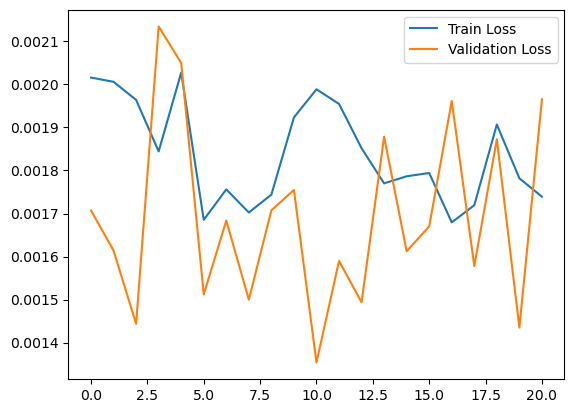

In [ ]:
# Plot Learning Curve
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.legend()
plt.show()

In [ ]:
# Prediksi dan Inverse Scaling
predict = best_model.predict(x_val)
predict_original_scale = scaler.inverse_transform(predict)
y_val_original_scale = scaler.inverse_transform(y_val)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step


In [11]:
from sklearn.metrics import mean_squared_error
from math import sqrt

# Flatten untuk evaluasi
y_flat = y_val_original_scale.reshape(-1)
predict_flat = predict_original_scale.reshape(-1)

# Evaluasi performa
mape_value = mean_absolute_percentage_error(y_flat, predict_flat) * 100
mae = np.mean(np.abs(predict_flat - y_flat))
rmse = sqrt(mean_squared_error(y_flat, predict_flat))
r2_value = r2_score(y_flat, predict_flat)

print(f'MAPE on Testing Data: {mape_value:.4f}%')
print(f'MAE on Testing Data: {mae:.4f}')
print(f'RMSE on Testing Data: {rmse:.4f}')
print(f'R2 Score on Testing Data: {r2_value:.4f}')

MAPE on Testing Data: 1.2404%
MAE on Testing Data: 7.2368
RMSE on Testing Data: 9.6663
R2 Score on Testing Data: 0.9408


In [ ]:
# Evaluasi pada training data
predict_train = best_model.predict(x_train)
predict_train_original_scale = scaler.inverse_transform(predict_train)
y_train_original_scale = scaler.inverse_transform(y_train)

# Flatten untuk evaluasi training
y_train_flat = y_train_original_scale.reshape(-1)
predict_train_flat = predict_train_original_scale.reshape(-1)

# Evaluasi performa pada training data
mape_train = mean_absolute_percentage_error(y_train_flat, predict_train_flat) * 100
mae = np.mean(np.abs(predict_train_flat - y_train_flat))
rmse = sqrt(mean_squared_error(y_train_flat, predict_train_flat))
r2_train = r2_score(y_train_flat, predict_train_flat)

print(f'MAPE on Training Data: {mape_train:.4f}%')
print(f'MAE on Training Data: {mae:.4f}')
print(f'RMSE on Training Data: {rmse:.4f}')
print(f'R2 Score on Training Data: {r2_train:.4f}')

30/30 ━━━━━━━━━━━━━━━━━━━━ 0s 8ms/step
MAPE on Training Data: 0.9523%
MAE on Training Data: 5.7961
RMSE on Training Data: 7.1330
R2 Score on Training Data: 0.9876


In [ ]:
best_model.save('best_tcn_model.keras')

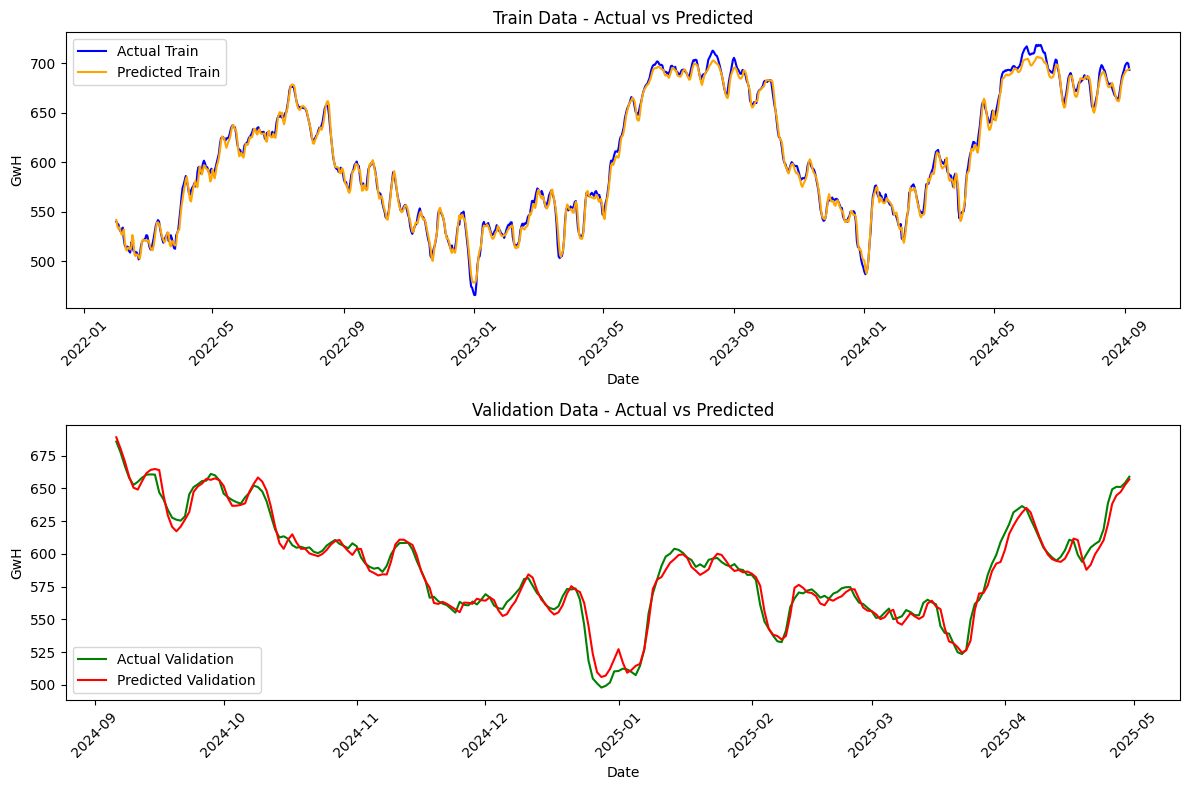

In [ ]:
date_train = data['date'].iloc[lookback_window:train_size + lookback_window]
date_val = data['date'].iloc[train_size + lookback_window:]

# Pastikan panjang data tanggal sesuai dengan data plot
date_train = date_train[:len(y_train_original_scale)]
date_val = date_val[:len(y_val_original_scale)]

# Konversi tanggal ke datetime objects
date_train = pd.to_datetime(date_train, format='%d/%m/%Y')
date_val = pd.to_datetime(date_val, format='%d/%m/%Y')

plt.figure(figsize=(12, 8))

# Plot data training
plt.subplot(2, 1, 1)
plt.plot(date_train, y_train_original_scale, label='Actual Train', color='blue')
plt.plot(date_train, predict_train_original_scale, label='Predicted Train', color='orange')
plt.title('Train Data - Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('GwH')
plt.legend()
plt.xticks(rotation=45)
plt.grid(False)

# Plot data validasi
plt.subplot(2, 1, 2)
plt.plot(date_val, y_val_original_scale, label='Actual Validation', color='green')
plt.plot(date_val, predict_original_scale, label='Predicted Validation', color='red')
plt.title('Validation Data - Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('GwH')
plt.legend()
plt.xticks(rotation=45)
plt.grid(False)

plt.tight_layout()
plt.show()

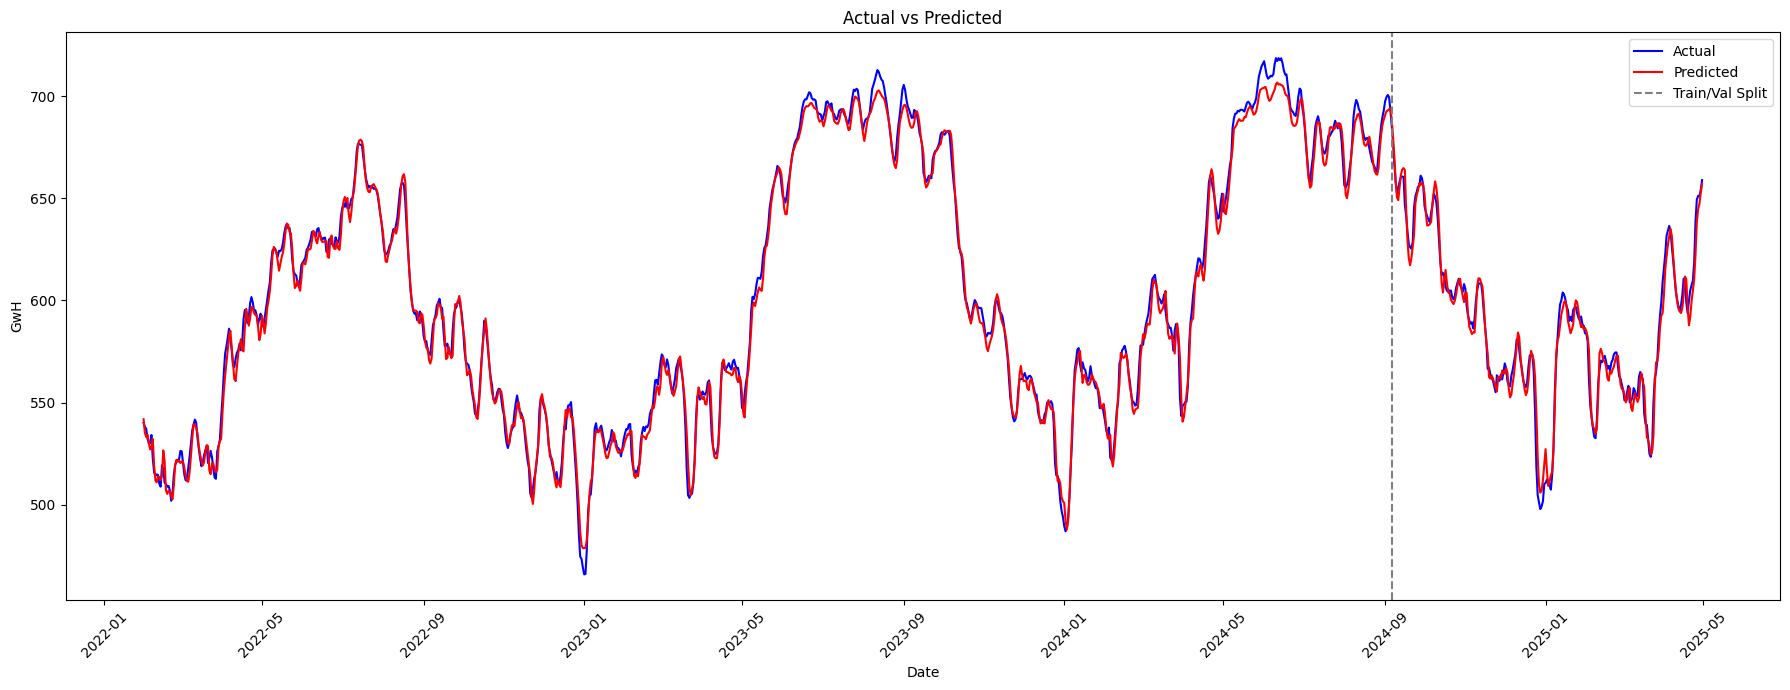

In [ ]:
full_dates = pd.to_datetime(data['date'].iloc[lookback_window:], dayfirst=True)

# Combine training and validation actual and predicted values
full_actual = np.concatenate((y_train_original_scale, y_val_original_scale))
full_predict = np.concatenate((predict_train_original_scale, predict_original_scale))

full_dates = full_dates[:len(full_actual)]

plt.figure(figsize=(18, 7))
plt.plot(full_dates, full_actual, label='Actual', color='blue')
plt.plot(full_dates, full_predict, label='Predicted', color='red')

split_date = full_dates.iloc[train_size]
plt.axvline(split_date, color='gray', linestyle='--', label='Train/Val Split')

plt.title('Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('GwH')
plt.legend()
plt.xticks(rotation=45)
plt.grid(False)
plt.tight_layout()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 56ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 71ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 43ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 49ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 152ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 77ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 45ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 36ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 39ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 50ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 46ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 55ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 44ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 52ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 48ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 72ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 34ms/step
1/1 ━━━━━━━

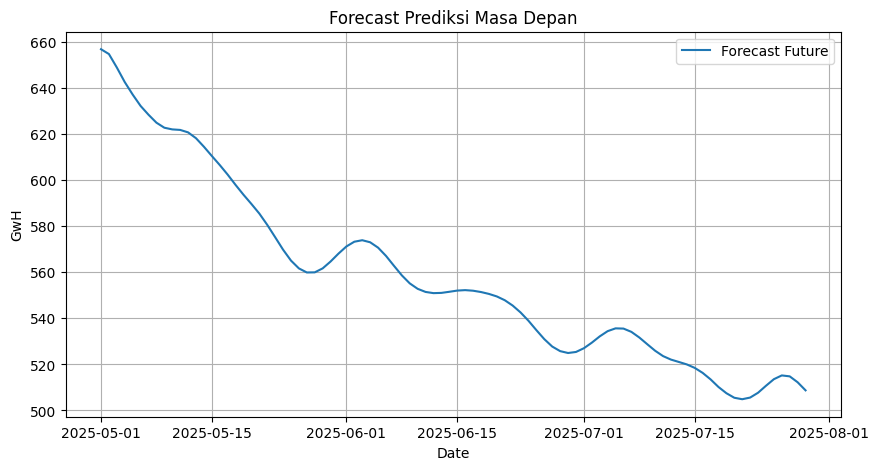

In [ ]:
n_forecast = 90  # jumlah hari ke depan
forecast_input = x_val[-1]
forecast_input = forecast_input.reshape(1, forecast_input.shape[0], 1)

future_forecast_scaled = []

for _ in range(n_forecast):
    pred = best_model.predict(forecast_input)
    future_forecast_scaled.append(pred[0, 0])

    # Perbarui input window: geser dan tambahkan prediksi terbaru
    new_input = np.append(forecast_input[0, 1:], [[pred[0, 0]]], axis=0)
    forecast_input = new_input.reshape(1, new_input.shape[0], 1)

# Inverse transform hasil prediksi
future_forecast_scaled = np.array(future_forecast_scaled).reshape(-1, 1)
future_forecast = scaler.inverse_transform(future_forecast_scaled)

# Generate future dates based on the last date in the original data
last_date = pd.to_datetime(data['date'], format='%d/%m/%Y').iloc[-1]
future_dates = pd.date_range(start=last_date + pd.Timedelta(days=1), periods=n_forecast, freq='D')

# Plot prediksi masa depan
plt.figure(figsize=(10,5))
plt.plot(future_dates, future_forecast, label="Forecast Future")
plt.title("Forecast Prediksi Masa Depan")
plt.xlabel("Date")
plt.ylabel("GwH")
plt.grid(True)
plt.legend()
plt.show()

Could not infer frequency, defaulting to daily. Error: 'DatetimeIndexResampler' object has no attribute 'index'


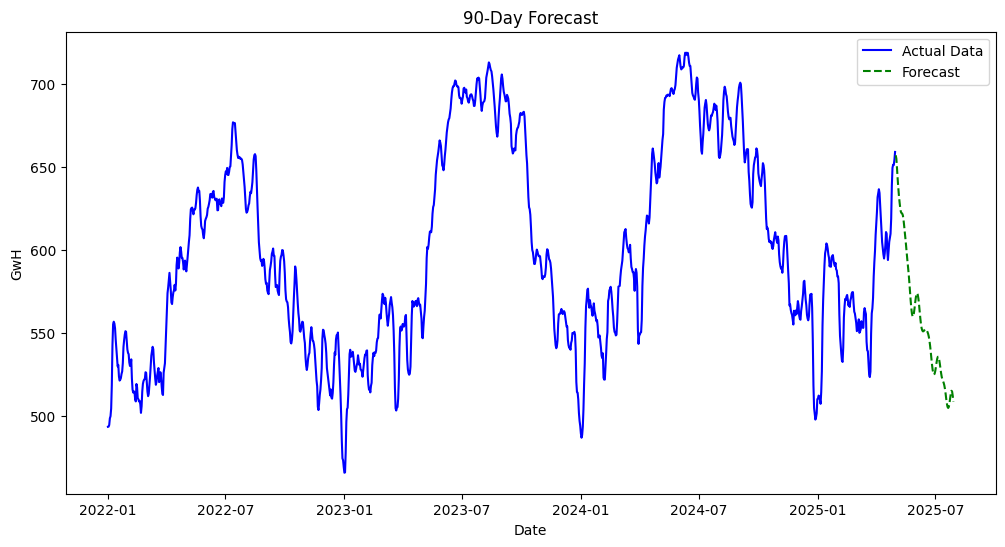

In [ ]:
data['date'] = pd.to_datetime(data['date'], dayfirst=True)
plt.figure(figsize=(12, 6))
actual_dates = data['date'][:len(df)]
plt.plot(actual_dates, df, label='Actual Data', color='blue')

last_actual_date = data['date'].iloc[len(df)-1]
try:
    freq = pd.infer_freq(data['date'])
    if freq is None:
        temp_series = pd.Series(index=data['date'])
        resampled_index = temp_series.resample('D').index
        freq = resampled_index.freq
        if freq is None:
             freq = 'D'
    future_dates = pd.date_range(start=last_actual_date, periods=n_forecast + 1, freq=freq)[1:]

except Exception as e:
    print(f"Could not infer frequency, defaulting to daily. Error: {e}")
    future_dates = pd.date_range(start=last_actual_date, periods=n_forecast + 1, freq='D')[1:]


plt.plot(future_dates, future_forecast, label='Forecast', color='green', linestyle='--')

plt.title('90-Day Forecast')
plt.xlabel('Date')
plt.ylabel('GwH')
plt.legend()
plt.grid(False)
plt.show()

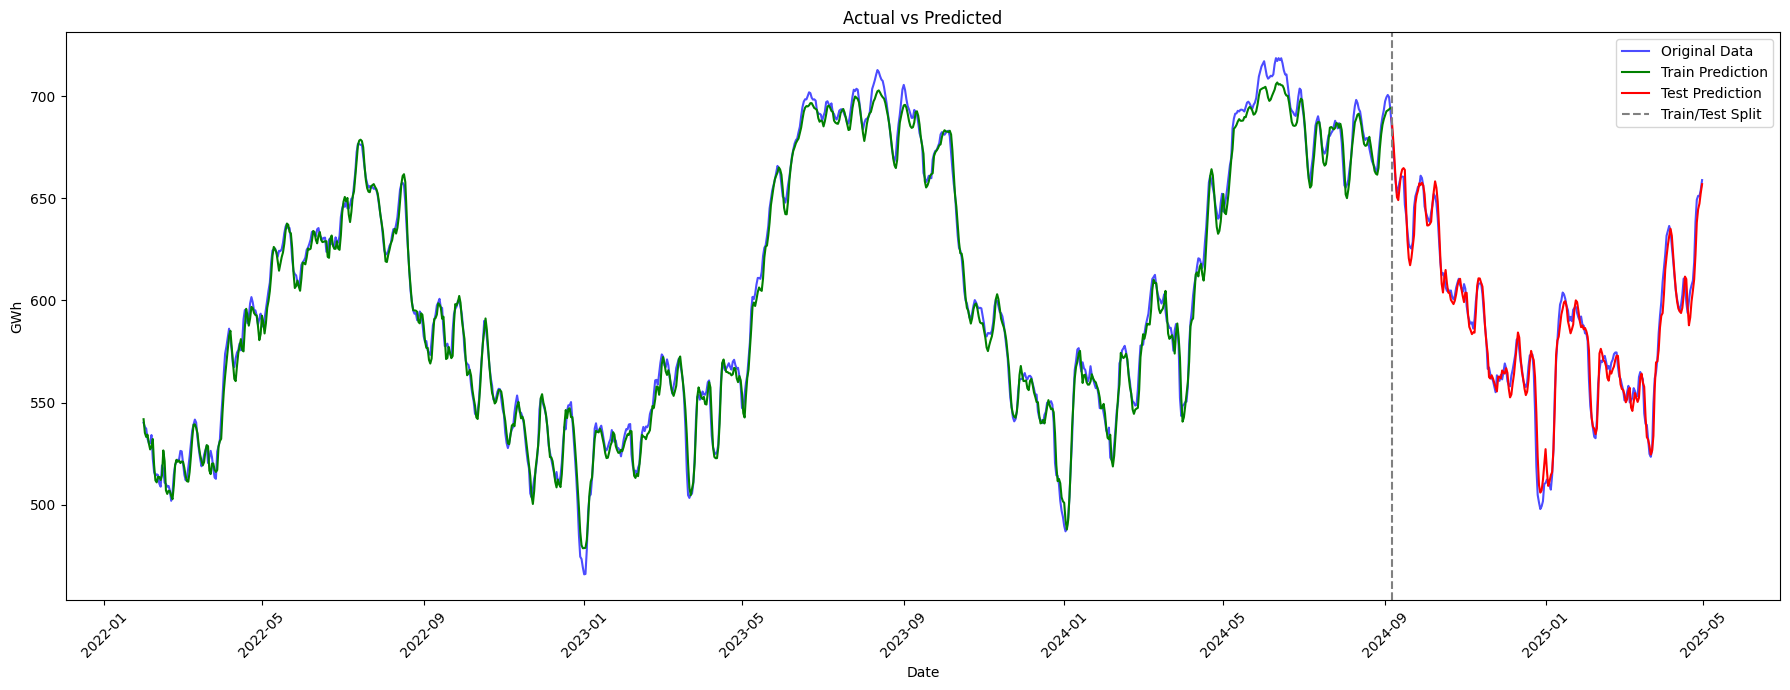

In [ ]:
full_data_original_scale = scaler.inverse_transform(df_scaled).flatten()
full_predict_original_scale = full_predict.flatten()
split_index = train_size

# Use full_dates for the x-axis of the original data plot
original_dates = pd.to_datetime(data['date'].iloc[lookback_window:], dayfirst=True)

train_dates = full_dates[:split_index]
test_dates = full_dates[split_index:]

plt.figure(figsize=(18, 7))
# Slice full_data_original_scale to match the length of original_dates
plt.plot(original_dates, full_data_original_scale[lookback_window:], label='Original Data', color='blue', alpha=0.7)
plt.plot(train_dates, full_predict_original_scale[:split_index], label='Train Prediction', color='green')
plt.plot(test_dates, full_predict_original_scale[split_index:], label='Test Prediction', color='red')

split_date = full_dates.iloc[split_index]
plt.axvline(split_date, color='gray', linestyle='--', label='Train/Test Split')

plt.title('Actual vs Predicted')
plt.xlabel('Date')
plt.ylabel('GWh')
plt.legend()
plt.xticks(rotation=45)
plt.grid(False)
plt.tight_layout()
plt.show()

In [ ]:
forecast_df = pd.DataFrame({
    'Date': future_dates,
    'Forecast GWh values': future_forecast.flatten()
})

display(forecast_df)

,Date,Forecast GWh values
0,2025-05-01,656.876892
1,2025-05-02,654.781555
2,2025-05-03,648.932434
3,2025-05-04,642.610779
4,2025-05-05,637.191833
...,...,...
85,2025-07-25,513.595154
86,2025-07-26,515.226746
87,2025-07-27,514.822388
88,2025-07-28,512.255493


In [8]:
# cek mode akhir
from tensorflow.keras.models import load_model

best_model = load_model("/content/best_tcn_model.keras")

In [9]:
# Prediksi dan Inverse Scaling
predict = best_model.predict(x_val)
predict_original_scale = scaler.inverse_transform(predict)
y_val_original_scale = scaler.inverse_transform(y_val)

8/8 ━━━━━━━━━━━━━━━━━━━━ 1s 82ms/step


In [10]:
from sklearn.metrics import mean_squared_error
from math import sqrt

# Flatten untuk evaluasi
y_flat = y_val_original_scale.reshape(-1)
predict_flat = predict_original_scale.reshape(-1)

# Evaluasi performa
mape_value = mean_absolute_percentage_error(y_flat, predict_flat) * 100
mae = np.mean(np.abs(predict_flat - y_flat))
rmse = sqrt(mean_squared_error(y_flat, predict_flat))
r2_value = r2_score(y_flat, predict_flat)

print(f'MAPE on Testing Data: {mape_value:.4f}%')
print(f'MAE on Testing Data: {mae:.4f}')
print(f'RMSE on Testing Data: {rmse:.4f}')
print(f'R2 Score on Testing Data: {r2_value:.4f}')

MAPE on Testing Data: 1.2404%
MAE on Testing Data: 7.2368
RMSE on Testing Data: 9.6663
R2 Score on Testing Data: 0.9408
